# TP2: Algoritmo Genético para diseñar un rover marciano (DEAP)

Este notebook evoluciona el diseño de un rover de seis ruedas con suspensión rocker-bogie mediante un Algoritmo Genético implementado con la librería DEAP (https://deap.readthedocs.io/en/master/). Cada individuo es un cromosoma de 15 genes reales en [0, 1] que se decodifican en las medidas físicas del rover: chasis, balancines y bogies, ruedas, motor, batería y parámetros del controlador de manejo. La aptitud de un diseño es la distancia media (en metros) que recorre sobre los terrenos de la generación, medida con una simulación física en MuJoCo sobre una pista construida con el relieve real del cráter Jezero. Las restricciones de la misión se tratan con las reglas de factibilidad de Deb (un diseño legal siempre supera a uno ilegal, y entre ilegales gana el que menos viola las restricciones), y la aptitud se maximiza. Al terminar, el mejor diseño se valida en 5 terrenos que no vio durante la evolución.

## 0) Preparar el ambiente

El notebook tiene dos modos, que se eligen con `RUN_SIMULATION` en la sección 2:

- **Modo simulación** (`RUN_SIMULATION = True`, local): corre el AG con el simulador. Necesita el repositorio completo y MuJoCo. Desde la carpeta del proyecto:

  ```
  uv sync
  uv run --with jupyterlab jupyter lab TP2_AG_Rover.ipynb
  ```

  `uv sync` instala las dependencias del proyecto, incluido `ipykernel`. También se puede abrir el notebook en VS Code y elegir como kernel el entorno `.venv` del proyecto.

- **Modo solo resultados** (`RUN_SIMULATION = False`, el valor por defecto; por ejemplo en Google Colab): no usa el simulador. Carga una corrida ya terminada (sus archivos `run.json` y `generations.csv`) y regenera las tablas y los gráficos solo con numpy, DEAP y matplotlib. En Colab, descomentar las líneas de la celda siguiente y ejecutarla una vez: clona el repositorio e instala DEAP (numpy y matplotlib ya vienen instalados en Colab).

In [1]:
#@title PREPARAR EL AMBIENTE
# Google Colab, modo solo resultados: descomentar estas tres líneas y ejecutar la celda una sola vez.
# !git clone <URL_DEL_REPOSITORIO> tp2-ag-rover-marciano
# %cd tp2-ag-rover-marciano
# !pip install deap

# Verificación del ambiente (no instala nada).
import importlib.util
import sys

print("Python", sys.version.split()[0])
print("MuJoCo disponible para el modo simulación:", importlib.util.find_spec("mujoco") is not None)

Python 3.14.3
MuJoCo disponible para el modo simulación: True


## 1) Importar librerías

Además de numpy, DEAP y matplotlib se importan los módulos del proyecto que **no** dependen del simulador. El simulador (`evolve.py`, que importa MuJoCo) solo se carga en la sección 4 si `RUN_SIMULATION = True`.

In [2]:
#@title IMPORTAR LIBRERÍAS
%matplotlib inline
import os
from importlib import metadata
import sys
from pathlib import Path

# El código del AG está en la carpeta codigo/ del repositorio
sys.path.insert(0, str(Path("codigo").resolve()))

import numpy as np
import matplotlib
from deap import base, creator, tools
from IPython.display import Markdown, display

# Módulos del proyecto que no dependen del simulador:
import ga                 # el AG sobre DEAP: GAConfig, make_toolbox, elitismo, mutación adaptativa, RunLogger
import genome_spec        # los 15 genes y su decodificación en valores físicos
import reference_rovers   # el diseño de referencia (tipo Perseverance, Tabla 4)
import plot_run           # los gráficos de una corrida a partir de su CSV
import notebook_support   # tablas y gráficos de este notebook

print(f"numpy {np.__version__} | DEAP {metadata.version('deap')} | matplotlib {matplotlib.__version__}")
print("Librerías importadas")

numpy 2.5.4 | DEAP 1.4.4 | matplotlib 3.11.2
Librerías importadas


## 2) Establecer parámetros generales de la Corrida

Los valores por defecto son los de la **Tabla 1** de la entrega parcial (equivalen a `evolve.py --preset normal`). Como en la demo de la cátedra, los métodos alternativos quedan indicados en comentarios: para probar otro, cambiar el valor (en Colab, con el formulario de `#@param`).

Las carpetas de resultados (`RUN_DIR`, `RANDOM_DIR`, `EXPERIMENT_DIR`) se usan en el modo solo resultados; también se pueden indicar con las variables de entorno `TP2_RUN_DIR`, `TP2_RANDOM_DIR` y `TP2_EXPERIMENT_DIR`.

In [3]:
#@title PARÁMETROS DE LA CORRIDA (Tabla 1 de la entrega parcial)

# --- Población y corrida ---
# N: individuos (diseños de rover) por generación
POPULATION_SIZE = 30  #@param {type:"integer"}
# Generaciones (la generación 0 es la población inicial)
GENERATIONS = 30  #@param {type:"integer"}
# Terrenos (semillas de rocas) en los que se evalúa cada diseño de una generación; la distancia se promedia
TERRAINS_PER_GENERATION = 2  #@param {type:"integer"}
# Terrenos no vistos durante la evolución, para validar al final los mejores diseños
VALIDATION_TERRAINS = 5  #@param {type:"integer"}
# Semilla de la corrida: todo lo aleatorio (población inicial, operadores y terrenos) deriva de ella
SEED = 1  #@param {type:"integer"}

# --- Selección ---
# "tournament": torneo (tools.selTournament) | "roulette": ruleta (tools.selRoulette) sobre la aptitud desplazada f - min(f)
SELECTION = "tournament"  #@param ["tournament", "roulette"]
# SELECTION = "roulette"
# k: participantes de cada torneo
TOURNAMENT_SIZE = 3  #@param {type:"integer"}

# --- Cruzamiento ---
# "blx": BLX-alfa (tools.cxBlend) | "binomial": cruce binomial (tools.cxUniform)
CROSSOVER = "blx"  #@param ["blx", "binomial"]
# CROSSOVER = "binomial"
# Probabilidad de cruzar cada pareja seleccionada
CROSSOVER_RATE = 0.9  #@param {type:"number"}
# Alfa del cruce BLX-alfa
BLX_ALPHA = 0.3  #@param {type:"number"}
# Con cruce binomial: probabilidad de intercambiar cada gen entre los dos hijos
BINOMIAL_GENE_RATE = 0.5  #@param {type:"number"}

# --- Mutación gaussiana por gen (tools.mutGaussian) ---
# Probabilidad de mutar cada gen (constante)
MUTATION_GENE_RATE = 0.1  #@param {type:"number"}
# Sigma con la población diversa (y sigma fijo si la mutación no es adaptativa)
SIGMA_MIN = 0.1  #@param {type:"number"}
# Sigma con la población convergida
SIGMA_MAX = 0.3  #@param {type:"number"}
# True: sigma se adapta según la diversidad de la población | False: sigma fijo = SIGMA_MIN
ADAPTIVE_MUTATION = True  #@param {type:"boolean"}
# ADAPTIVE_MUTATION = False

# --- Elitismo ---
# Mejores individuos que pasan sin cambios a la generación siguiente
ELITE_COUNT = 2  #@param {type:"integer"}

# --- Modo del notebook ---
# True: corre el AG con el simulador (local, requiere MuJoCo) | False: solo carga resultados de RUN_DIR
RUN_SIMULATION = False  #@param {type:"boolean"}
# Tope de tiempo simulado por rover, en segundos (None: el que se deriva de la pista)
MAX_SIM_TIME_S = None
# Procesos de simulación en paralelo (None: uno por núcleo)
WORKERS = None
# Carpeta nueva para una corrida lanzada desde el notebook
OUTPUT_DIR = notebook_support.default_output_dir()

# --- Carpetas de resultados ---
# Una corrida terminada (carpeta con run.json y generations.csv)
RUN_DIR = Path(os.environ.get("TP2_RUN_DIR", "logs-corridas/c1-base"))
# Opcional: una búsqueda aleatoria con el mismo presupuesto, para comparar
RANDOM_DIR = Path(os.environ.get("TP2_RANDOM_DIR", "logs-corridas/random-search"))
# Opcional: una carpeta con varias corridas (AG y búsqueda aleatoria) para la comparación de la sección 5
EXPERIMENT_DIR = Path(os.environ.get("TP2_EXPERIMENT_DIR", "logs-corridas"))

print("Parámetros de la corrida definidos")

Parámetros de la corrida definidos


## 3) Inicializar objetos de DEAP para utilizar

- **Función de aptitud (a maximizar):** `creator.FitnessMax`, con `weights=(1.0,)`. Cada individuo se decodifica en un rover y se simula en cada terreno de la generación. Si el diseño es legal, su aptitud es la distancia media recorrida (m); si viola alguna restricción de la misión (por ejemplo, la masa o el tamaño máximos), su aptitud es −(1 + violación total), siempre negativa (reglas de Deb). La evaluación no se registra como `toolbox.evaluate` porque la generación completa se simula como un solo lote en paralelo (`evolve.GenerationEvaluator`).
- **Cromosoma:** `creator.Individual`, una lista de 15 genes reales en [0, 1]; cada gen se convierte en un valor físico dentro de su rango (`genome_spec.decode`).
- **Población inicial:** genes uniformes en [0, 1], generados a partir de la semilla de la corrida (`ga.initial_population`).
- **Operadores:** `ga.make_toolbox(config)` los registra en un `base.Toolbox` de DEAP; es la misma función que usa `evolve.py`.

In [4]:
#@title FUNCIÓN DE APTITUD Y ESTRUCTURA DEL CROMOSOMA
# ga.py crea con DEAP la aptitud y el tipo de individuo al importarse:
#   creator.create("FitnessMax", base.Fitness, weights=(1.0,))
#   creator.create("Individual", list, fitness=creator.FitnessMax)
print(f"Aptitud: creator.FitnessMax, pesos {creator.FitnessMax.weights} (se maximiza)")
print(f"Individuo: creator.Individual, lista de {genome_spec.GENOME_LENGTH} genes reales en [0, 1]")

# Configuración del AG con los parámetros de la sección 2 (ga.GAConfig valida cada valor)
ga_config = ga.GAConfig(
    population_size=POPULATION_SIZE, seed=SEED, selection=SELECTION, tournament_size=TOURNAMENT_SIZE,
    crossover=CROSSOVER, crossover_rate=CROSSOVER_RATE, blx_alpha=BLX_ALPHA, binomial_indpb=BINOMIAL_GENE_RATE,
    mutation_gene_rate=MUTATION_GENE_RATE, mutation_sigma=SIGMA_MIN, sigma_max=SIGMA_MAX,
    adaptive_mutation=ADAPTIVE_MUTATION, elite_count=ELITE_COUNT)

# Población inicial: la misma generación 0 que crea ga.run con esta semilla
initial_population = ga.to_individuals(ga.initial_population(ga_config, np.random.default_rng(SEED)))
print(f"Población inicial: {len(initial_population)} individuos")
print("Primer individuo:", [round(gene, 3) for gene in initial_population[0]])

Aptitud: creator.FitnessMax, pesos (1.0,) (se maximiza)
Individuo: creator.Individual, lista de 15 genes reales en [0, 1]
Población inicial: 30 individuos
Primer individuo: [0.512, 0.95, 0.144, 0.949, 0.312, 0.423, 0.828, 0.409, 0.55, 0.028, 0.754, 0.538, 0.33, 0.788, 0.303]


In [5]:
#@title OPERADORES GENÉTICOS
# El toolbox se arma con la función real del proyecto (la misma que usa evolve.py)
toolbox = ga.make_toolbox(ga_config)

print("Operadores registrados en el toolbox:")
for line in notebook_support.operator_lines(toolbox):
    print("  " + line)
print(f"Cruce: cada pareja seleccionada se cruza con probabilidad {ga_config.crossover_rate:g}.")
if ga_config.adaptive_mutation:
    print(f"Mutación adaptativa: en cada generación se llama a toolbox.mutate(individuo, sigma=σ_g), con σ_g entre "
          f"{ga_config.mutation_sigma:g} (población diversa) y {ga_config.sigma_max:g} (población convergida).")
else:
    print(f"Mutación con σ fijo = {ga_config.mutation_sigma:g}.")
print(f"Elitismo: los {ga_config.elite_count} mejores pasan sin cambios a la generación siguiente (tools.selBest).")
print("Después del cruce y de la mutación, cada gen se refleja dentro de [0, 1] (ga.reflect).")

Operadores registrados en el toolbox:
  toolbox.register("select", tools.selTournament, tournsize=3)
  toolbox.register("mate", tools.cxBlend, alpha=0.3)
  toolbox.register("mutate", tools.mutGaussian, mu=0.0, sigma=0.1, indpb=0.1)
Cruce: cada pareja seleccionada se cruza con probabilidad 0.9.
Mutación adaptativa: en cada generación se llama a toolbox.mutate(individuo, sigma=σ_g), con σ_g entre 0.1 (población diversa) y 0.3 (población convergida).
Elitismo: los 2 mejores pasan sin cambios a la generación siguiente (tools.selBest).
Después del cruce y de la mutación, cada gen se refleja dentro de [0, 1] (ga.reflect).


Con los valores de la Tabla 1, el toolbox equivale a estas líneas de DEAP (las alternativas, comentadas):

```python
toolbox.register("select", tools.selTournament, tournsize=3)                  # selección por torneo, k = 3
# toolbox.register("select", ga.select_roulette)                              # alternativa: ruleta sobre f - min(f) + 1e-6
toolbox.register("mate", tools.cxBlend, alpha=0.3)                            # cruce BLX-α, α = 0.3, con p = 0.9
# toolbox.register("mate", tools.cxUniform, indpb=0.5)                        # alternativa: cruce binomial
toolbox.register("mutate", tools.mutGaussian, mu=0.0, sigma=0.1, indpb=0.1)   # mutación gaussiana, p = 0.1 por gen
```

La ruleta usa la aptitud desplazada f − min(f) + 10⁻⁶ porque `tools.selRoulette` necesita aptitudes positivas y la de un diseño ilegal es negativa. La **mutación adaptativa** cambia σ según la convergencia de la población: σ_g = σ_min + (σ_max − σ_min) · clip(1 − D_g / D_0, 0, 1), donde D es la diversidad (desvío estándar medio por gen) y D_0 la de la generación 0. Con la población diversa los pasos son pequeños; a medida que converge, crecen.

**Ejemplo de individuo:** el diseño de referencia (tipo Perseverance, Tabla 4 de la entrega parcial) decodificado en valores físicos.

In [6]:
#@title EJEMPLO DE INDIVIDUO: DISEÑO DE REFERENCIA DECODIFICADO
reference_genome = reference_rovers.genome(reference_rovers.PERSEVERANCE_LIKE)
display(Markdown(notebook_support.design_table(reference_genome)))

| Gen | Descripción | Valor en el cromosoma (0 a 1) | Valor físico | Unidad |
|---|---|---|---|---|
| chassis_length_m | largo del chasis | 0.250 | 2 | m |
| track_width_m | distancia lateral entre las ruedas izquierdas y derechas | 0.533 | 2.3 | m |
| chassis_height_m | alto del chasis | 0.200 | 0.4 | m |
| rocker_pivot_height_m | altura del pivote del balancín sobre los ejes de las ruedas | 0.188 | 0.55 | m |
| rocker_pivot_offset | posición del pivote del balancín a lo largo del chasis | 0.500 | 0 | fracción del largo del chasis |
| rocker_front_arm_m | brazo del balancín: pivote a rueda delantera | 0.700 | 1.2 | m |
| rocker_rear_arm_m | brazo del balancín: pivote al pivote del bogie | 0.556 | 0.8 | m |
| bogie_length_m | largo del bogie: entre ruedas media y trasera | 0.600 | 1 | m |
| wheel_diameter_m | diámetro de las seis ruedas | 0.450 | 0.525 | m |
| wheel_width_m | ancho de las seis ruedas | 0.750 | 0.4 | m |
| motor_peak_torque_nm | torque pico del motor de cada rueda | 0.903 | 120 | N·m |
| battery_energy_wh | energía de la batería | 0.667 | 2000 | Wh |
| target_speed_mps | velocidad crucero | 0.286 | 0.5 | m/s |
| torque_limit_fraction | fracción del torque pico que usa el controlador | 0.714 | 0.8 | fracción (0 a 1) |
| slope_brake | cuánto frena el controlador según la pendiente (0 = nunca) | 0.500 | 0.5 | adimensional (0 a 1) |

## 4) Ejecutar la corrida del algoritmo mostrando resultados

- **Modo simulación:** corre `evolve.py` (el programa del proyecto) en este mismo proceso con los parámetros de la sección 2 y muestra una línea por generación: aptitud del mejor y promedio, cuántos diseños son legales y llegaron a la meta, diversidad y σ. Al final valida los 3 mejores diseños de la población final y el de referencia en los terrenos de validación, y guarda la corrida en `OUTPUT_DIR`. Con los valores de la Tabla 1 son 30 × 30 × 2 = 1800 simulaciones: puede tardar decenas de minutos.
- **Modo solo resultados:** carga la corrida de `RUN_DIR`.

En ambos modos se muestran después los resultados leídos de los archivos de la corrida.

### Ciclo de una generación

Este es el código real que arma cada generación nueva (`codigo/ga.py`), como el ciclo de la demo de la cátedra: los mejores pasan sin cambios (elitismo, `tools.selBest`), se seleccionan los padres con `toolbox.select`, y `vary` los cruza (`toolbox.mate`, con probabilidad p_c), los muta (`toolbox.mutate` con el σ de esta generación) y refleja cada gen dentro de [0, 1]. La evaluación (la simulación de cada rover) se hace después, para toda la generación en paralelo.

In [7]:
#@title CICLO DE UNA GENERACIÓN (código de codigo/ga.py)
import inspect

print(inspect.getsource(ga.next_generation))
print(inspect.getsource(ga.vary))

def next_generation(population: np.ndarray, evaluations, config: GAConfig, state: GAState,
                    rng: np.random.Generator, toolbox: base.Toolbox | None = None) -> tuple[np.ndarray, GAState]:
    """Elitism + `toolbox.select` + `vary` (crossover, Gaussian mutation, reflection). Returns (new population, new
    state). `toolbox` defaults to `make_toolbox(config)`; DEAP's draws come from a stream seeded by `rng`."""
    if len(evaluations) != len(population):
        raise ValueError(f"expected {len(population)} evaluations, got {len(evaluations)}")
    toolbox = make_toolbox(config) if toolbox is None else toolbox
    new_state = update_state(state, population, config)
    individuals = to_individuals(population, _fitness_array(evaluations))
    elites = tools.selBest(individuals, config.elite_count)  # copied unchanged; sorted() is stable: first wins ties
    with _python_random(int(rng.integers(2**63))):
        parents = toolbox.select(individuals, config.population_size

In [8]:
#@title EJECUCIÓN DE LA CORRIDA
if RUN_SIMULATION:
    arguments = notebook_support.evolve_arguments(
        ga_config, generations=GENERATIONS, seeds_per_generation=TERRAINS_PER_GENERATION,
        validation_seeds=VALIDATION_TERRAINS, out_dir=OUTPUT_DIR, max_sim_time_s=MAX_SIM_TIME_S, workers=WORKERS)
    print("Comando equivalente en una terminal:")
    print("  " + notebook_support.command_line(arguments))
    RUN_DIR = notebook_support.run_evolve(arguments)  # imprime una línea por generación
else:
    print(f"Modo resultados (RUN_SIMULATION = False): se cargan los resultados de {RUN_DIR}")

run = notebook_support.load_run(RUN_DIR)
display(Markdown(notebook_support.run_summary(run)))
differences = notebook_support.parameter_differences(
    run, ga_config, GENERATIONS, TERRAINS_PER_GENERATION, VALIDATION_TERRAINS)
if differences:
    print("Atención: la corrida cargada no usó todos los parámetros de la sección 2:")
    for difference in differences:
        print("  - " + difference)

Modo resultados (RUN_SIMULATION = False): se cargan los resultados de logs-corridas\c1-base


- **Corrida:** `logs-corridas\c1-base` (AG, estado `finished`)
- **Tamaño:** 30 individuos x 30 generaciones, 2 terrenos por generación, semilla 1
- **Métodos:** selección torneo (k=3); cruce BLX-α (α=0.3), p=0.9; mutación gaussiana, p_gen=0.1, σ 0.1–0.3 adaptativa; elitismo 2
- **Validación:** 5 terrenos no vistos durante la evolución

### Evolución por generación

Máximo y promedio de la aptitud de cada generación, diversidad de la población (desvío estándar medio por gen) y σ de mutación con el que se generó la generación siguiente. Cada generación se evalúa en terrenos distintos, así que la aptitud se lee como tendencia: el máximo de una generación puede ser menor que el de la anterior.

In [9]:
#@title TABLA POR GENERACIÓN
display(Markdown(notebook_support.generation_table(run)))

| Generación | Máximo | Promedio | Diversidad | σ de mutación |
|---|---|---|---|---|
| 0 | 193.79 | 5.60 | 0.278 | 0.100 |
| 1 | 67.46 | 6.35 | 0.245 | 0.124 |
| 2 | 64.61 | 18.02 | 0.197 | 0.159 |
| 3 | 233.35 | 59.83 | 0.152 | 0.191 |
| 4 | 185.93 | 44.40 | 0.139 | 0.200 |
| 5 | 247.68 | 82.11 | 0.118 | 0.215 |
| 6 | 333.87 | 130.79 | 0.106 | 0.224 |
| 7 | 334.97 | 157.09 | 0.117 | 0.216 |
| 8 | 324.10 | 211.70 | 0.109 | 0.222 |
| 9 | 335.89 | 171.16 | 0.109 | 0.222 |
| 10 | 336.25 | 184.56 | 0.126 | 0.209 |
| 11 | 351.21 | 272.75 | 0.114 | 0.218 |
| 12 | 360.67 | 203.34 | 0.108 | 0.222 |
| 13 | 214.70 | 183.01 | 0.114 | 0.218 |
| 14 | 372.45 | 213.60 | 0.094 | 0.232 |
| 15 | 372.46 | 300.36 | 0.104 | 0.225 |
| 16 | 372.46 | 312.63 | 0.101 | 0.227 |
| 17 | 372.46 | 311.72 | 0.101 | 0.228 |
| 18 | 372.46 | 246.40 | 0.110 | 0.221 |
| 19 | 372.46 | 254.34 | 0.105 | 0.224 |
| 20 | 372.46 | 289.56 | 0.114 | 0.218 |
| 21 | 223.21 | 201.95 | 0.112 | 0.220 |
| 22 | 348.35 | 180.51 | 0.097 | 0.230 |
| 23 | 372.46 | 310.76 | 0.090 | 0.235 |
| 24 | 372.46 | 306.14 | 0.093 | 0.233 |
| 25 | 372.47 | 302.59 | 0.081 | 0.242 |
| 26 | 372.46 | 318.05 | 0.090 | 0.235 |
| 27 | 372.46 | 237.15 | 0.087 | 0.238 |
| 28 | 372.46 | 186.01 | 0.096 | 0.231 |
| 29 | 372.46 | 343.31 | 0.089 | 0.236 |

### Mejor diseño obtenido y criterio de éxito

El mejor diseño es el mejor individuo de la población final (`final_best`; en una búsqueda aleatoria, `random_best`). Se valida en los terrenos no vistos y la corrida **resuelve el problema** si ese diseño es legal y llega a la meta en al menos 3 de los 5 terrenos de validación (criterio de la sección 6.3 de la entrega parcial). Como verificación adicional se informan las llegadas de los 3 mejores diseños.

In [10]:
#@title MEJOR DISEÑO, VALIDACIÓN Y CRITERIO DE ÉXITO
best = notebook_support.best_entry(run)
if best is not None:
    print(f"Mejor diseño: {best['label']} | aptitud de entrenamiento {best['training_fitness']:.2f}")
display(Markdown(notebook_support.best_design_table(run)))
display(Markdown(notebook_support.validation_table(best)))
display(Markdown(notebook_support.success_line(run)))
display(Markdown(notebook_support.top3_line(run)))

Mejor diseño: final_best | aptitud de entrenamiento 372.46


| Gen | Descripción | Valor en el cromosoma (0 a 1) | Valor físico | Unidad |
|---|---|---|---|---|
| chassis_length_m | largo del chasis | 0.332 | 2.164 | m |
| track_width_m | distancia lateral entre las ruedas izquierdas y derechas | 0.260 | 1.89 | m |
| chassis_height_m | alto del chasis | 0.360 | 0.48 | m |
| rocker_pivot_height_m | altura del pivote del balancín sobre los ejes de las ruedas | 0.091 | 0.473 | m |
| rocker_pivot_offset | posición del pivote del balancín a lo largo del chasis | 0.249 | -0.151 | fracción del largo del chasis |
| rocker_front_arm_m | brazo del balancín: pivote a rueda delantera | 0.476 | 0.976 | m |
| rocker_rear_arm_m | brazo del balancín: pivote al pivote del bogie | 0.189 | 0.47 | m |
| bogie_length_m | largo del bogie: entre ruedas media y trasera | 0.643 | 1.043 | m |
| wheel_diameter_m | diámetro de las seis ruedas | 0.614 | 0.607 | m |
| wheel_width_m | ancho de las seis ruedas | 0.282 | 0.213 | m |
| motor_peak_torque_nm | torque pico del motor de cada rueda | 0.992 | 147.2 | N·m |
| battery_energy_wh | energía de la batería | 0.213 | 778.6 | Wh |
| target_speed_mps | velocidad crucero | 0.963 | 0.974 | m/s |
| torque_limit_fraction | fracción del torque pico que usa el controlador | 0.871 | 0.909 | fracción (0 a 1) |
| slope_brake | cuánto frena el controlador según la pendiente (0 = nunca) | 0.109 | 0.109 | adimensional (0 a 1) |

| Terreno (semilla) | Distancia (m) | Causa de fin | ¿Llegó a la meta? |
|---|---|---|---|
| 1302828960 | 372.5 | llegó a la meta | sí |
| 899894886 | 372.5 | llegó a la meta | sí |
| 1371778638 | 372.5 | llegó a la meta | sí |
| 1512735633 | 92.0 | atascado | no |
| 1692859205 | 296.7 | atascado | no |

¿Resuelve el problema? **Sí**: el diseño `final_best` es legal y llegó a la meta en 3 de 5 terrenos de validación (el criterio pide al menos 3).

Top-3 validados, llegadas: final_best 3/5, final_2 3/5, final_3 3/5

### Diseño de referencia y búsqueda aleatoria (líneas de base)

El diseño de referencia (tipo Perseverance) se valida en los mismos terrenos que el mejor diseño. Si `RANDOM_DIR` tiene una búsqueda aleatoria con el mismo presupuesto de evaluaciones, se la compara con la corrida cargada.

In [11]:
#@title DISEÑO DE REFERENCIA
display(Markdown(notebook_support.validation_table(notebook_support.reference_entry(run))))
display(Markdown(notebook_support.reference_line(run)))

| Terreno (semilla) | Distancia (m) | Causa de fin | ¿Llegó a la meta? |
|---|---|---|---|
| 1302828960 | 343.6 | atascado | no |
| 899894886 | 324.3 | atascado | no |
| 1371778638 | 49.3 | atascado | no |
| 1512735633 | 42.1 | atascado | no |
| 1692859205 | 36.4 | atascado | no |

Diseño de referencia (tipo Perseverance): **No**: el diseño `reference` es legal y llegó a la meta en 0 de 5 terrenos de validación (el criterio pide al menos 3).

In [12]:
#@title BÚSQUEDA ALEATORIA (OPCIONAL)
if (RANDOM_DIR / "run.json").is_file():
    random_run = notebook_support.load_run(RANDOM_DIR)
    display(Markdown(notebook_support.comparison_table([run, random_run])))
    display(Markdown("Búsqueda aleatoria: " + notebook_support.success_line(random_run)))
else:
    print(f"No hay una búsqueda aleatoria en {RANDOM_DIR}: se omite la comparación (ver RANDOM_DIR en la sección 2).")

| Corrida | Tipo | Selección | Cruce | Mutación | Elitismo | Aptitud del mejor diseño | Distancia media de validación (m) | Llegadas | ¿Éxito? |
|---|---|---|---|---|---|---|---|---|---|
| c1-base | AG | torneo (k=3) | BLX-α (α=0.3), p=0.9 | gaussiana, p_gen=0.1, σ 0.1–0.3 adaptativa | 2 | 372.46 | 301.2 | 3/5 | sí |
| random-search | búsqueda aleatoria | — | — | — | — | 364.50 | 290.9 | 1/5 | no |

Búsqueda aleatoria: ¿Resuelve el problema? **No**: el diseño `random_best` es legal y llegó a la meta en 1 de 5 terrenos de validación (el criterio pide al menos 3).

## 5) Generar gráficos de la corrida

Los gráficos de la corrida se dibujan con `plot_run` a partir de su `generations.csv`, igual que los PNG que `evolve.py` guarda junto al CSV (`generations_fitness.png` y `generations_diversity.png`). Después, si `EXPERIMENT_DIR` tiene varias corridas, se las compara en una tabla y en un gráfico con la curva del máximo de cada una.

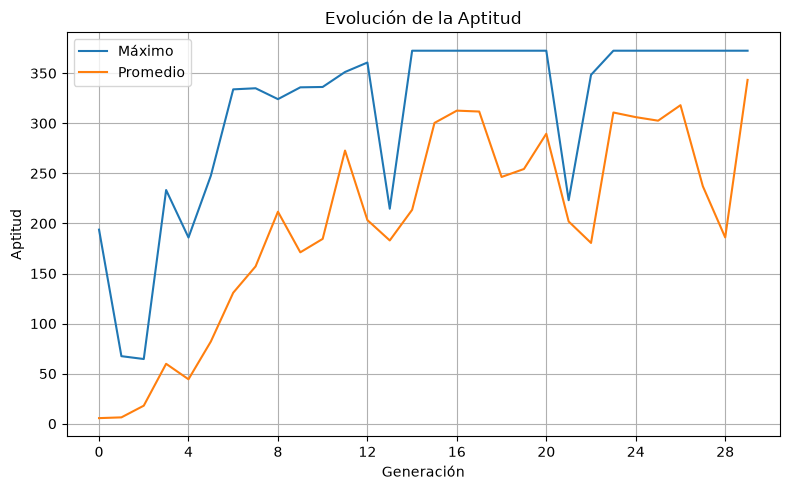

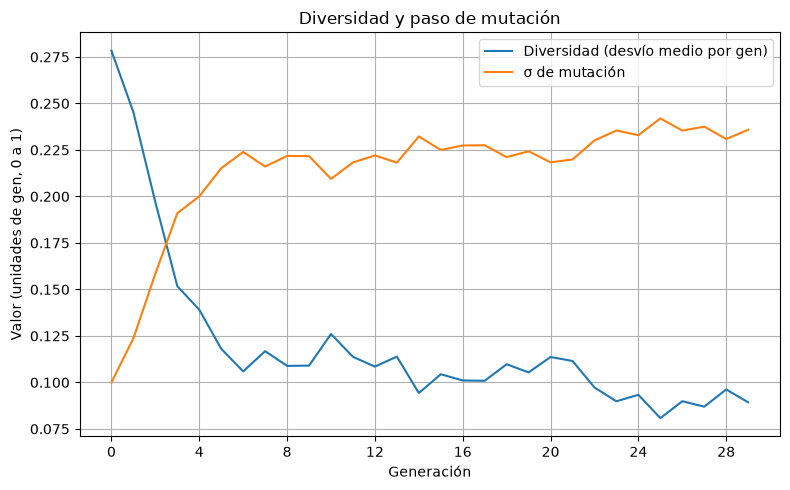

In [13]:
#@title MOSTRAR GRÁFICOS DE LA CORRIDA
title_suffix = "búsqueda aleatoria" if run.kind == "random_search" else ""
fitness_figure, _ = plot_run.fitness_figure(run.generations, title_suffix)
diversity_figure, _ = plot_run.diversity_figure(run.generations, title_suffix)
display(fitness_figure)
display(diversity_figure)

| Corrida | Tipo | Selección | Cruce | Mutación | Elitismo | Aptitud del mejor diseño | Distancia media de validación (m) | Llegadas | ¿Éxito? |
|---|---|---|---|---|---|---|---|---|---|
| c1-base | AG | torneo (k=3) | BLX-α (α=0.3), p=0.9 | gaussiana, p_gen=0.1, σ 0.1–0.3 adaptativa | 2 | 372.46 | 301.2 | 3/5 | sí |
| c2-ruleta | AG | ruleta | BLX-α (α=0.3), p=0.9 | gaussiana, p_gen=0.1, σ 0.1–0.3 adaptativa | 2 | 372.46 | 315.6 | 3/5 | sí |
| c3-binomial | AG | torneo (k=3) | binomial (p_gen=0.5), p=0.9 | gaussiana, p_gen=0.1, σ 0.1–0.3 adaptativa | 2 | 372.46 | 372.5 | 5/5 | sí |
| c4-sigma-fija | AG | torneo (k=3) | BLX-α (α=0.3), p=0.9 | gaussiana, p_gen=0.1, σ fija 0.1 | 2 | 372.46 | 306.2 | 3/5 | sí |
| c5-sin-elite | AG | torneo (k=3) | BLX-α (α=0.3), p=0.9 | gaussiana, p_gen=0.1, σ 0.1–0.3 adaptativa | 0 | 372.46 | 357.3 | 4/5 | sí |
| random-search | búsqueda aleatoria | — | — | — | — | 364.50 | 290.9 | 1/5 | no |

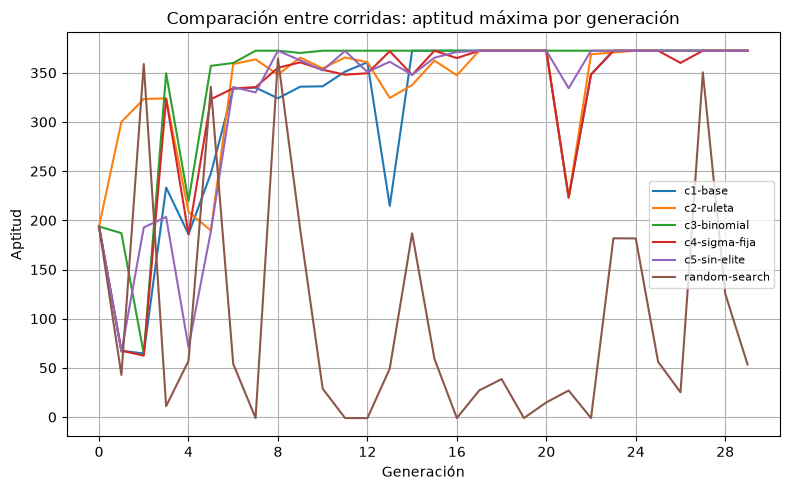

In [14]:
#@title COMPARACIÓN ENTRE CORRIDAS (OPCIONAL)
experiment = notebook_support.load_experiment(EXPERIMENT_DIR) if EXPERIMENT_DIR.is_dir() else []
if experiment:
    display(Markdown(notebook_support.comparison_table(experiment)))
    display(notebook_support.overlay_figure(experiment))
else:
    print(f"No hay corridas en {EXPERIMENT_DIR}: se omite la comparación (ver EXPERIMENT_DIR en la sección 2).")